In [26]:
# generate figs in here

import matplotlib.pyplot as plt
import numpy as np
import plotly.graph_objects as go

from pathlib import Path
current_file_path = Path().resolve().parent
current_file_path

PosixPath('/home/mag/variance-analysis')

In [99]:
neuron_idx = 400

In [2]:
dataset = 'dusz'
dataset_n = 6
#session = 'A1821-190910'
session = 'A1110-180612'

data_path = current_file_path / 'results' / dataset / f'Dataset_{dataset_n}' / session
rate_map = np.load('/home/mag/Space/results/dusz/Dataset_6/A1110-180612/hd_rate_map_n_hd_bins_17.npy')

print(rate_map.shape)

neuron_idx = 2
neuron_activations = rate_map[:, :, :, neuron_idx].flatten()

(11, 11, 17, 5)


In [197]:
# real pfeiffer neuron

fold_seed = 111
hdBinCount=17

#smoothRateMaps = np.load(f'/home/mag/Space/results/pfeiffer/smoothRateMaps_seed_{fold_seed}_hdBinCount_{hdBinCount}.npy') # smoothed xy map: n_bins, n_bins, n_neurons
hdRateMap = np.load(f'/home/mag/Space/results/pfeiffer/hd_rate_maps_nonselective_traj.npy') # firing rate per hd: n_bins, n_bins, n_rotations, n_neurons

print('shape:', hdRateMap.shape)

neuron_idx = 2

neuron_activations = hdRateMap[neuron_idx].flatten()


shape: (200, 17, 17, 17)


In [188]:
neuron_idx

56349

In [ ]:
# model neuron

dataset = 'pred-code'
which_model = 'small_world_random'
data_path = current_file_path / 'results' / dataset / which_model / ''

#model_reps = np.load(data_path / 'model_reps.npy')
model_reps = np.load('/home/mag/Space/results/small_world_r17/2d/uniform/predictive-coding-small-world-random-old/final/model_reps.npy')
#model_reps = np.load('/home/mag/Space/results/small_world_r17/2d/uniform/resnet50/conv5_block2_out/model_reps.npy')
_, n_neurons = model_reps.shape

neuron_idx = np.random.randint(0, n_neurons)
# 2088
# 2148
# 2159
# 2167
# 4257
# 6332
# 6379
# 3108
# 2102
# 1133

neuron_activations = np.maximum(model_reps[:, neuron_idx], 0)
print(model_reps.shape)

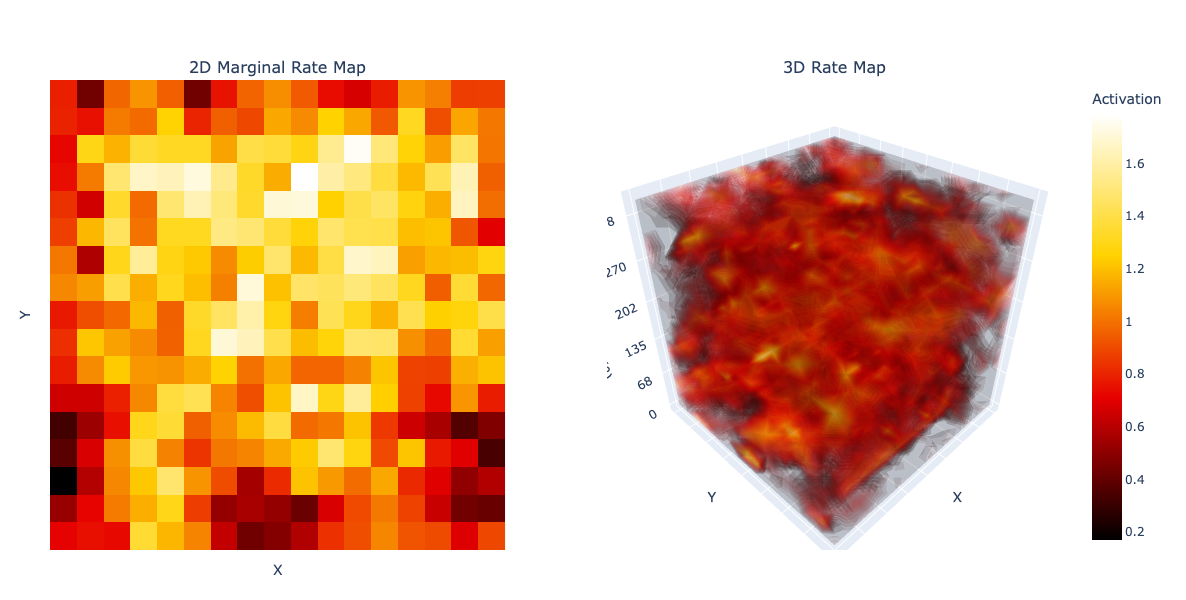

In [ ]:
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# assume neuron_activations is shape (17,17,17) and neuron_idx is defined
n_bins = 17 # 11

# 1) compute the flattened 2D map
reshaped_neuron = np.reshape(neuron_activations, (n_bins,n_bins,17))
marginals = np.nanmean(reshaped_neuron, axis=2)

# 2) build the meshgrid for the volume
a = np.arange(n_bins)
b = np.arange(n_bins)
c = np.arange(17)
xx, yy, zz = np.meshgrid(a, b, c, indexing='ij')
xx_flat, yy_flat, zz_flat = xx.flatten(), yy.flatten(), zz.flatten()
values_flat = neuron_activations.flatten()

# precompute degree labels for Z
deg_ticks = np.round(np.linspace(0, 360, 17)).astype(int).tolist()
tick_idx = list(range(0, 17, 3))

# 3) make subplots: heatmap + 3D scene
fig = make_subplots(
    rows=1, cols=2,
    specs=[[{"type": "heatmap"}, {"type": "scene"}]],
    subplot_titles=("2D Marginal Rate Map", "3D Rate Map")
)

# -- left: heatmap
fig.add_trace(
    go.Heatmap(
        z=marginals,
        x=np.arange(1, n_bins+1),
        y=np.arange(1, n_bins+1),
        colorscale="Hot",
        colorbar=dict(title="Activation") #(title="Firing rate <br>(spikes/sec)")
    ),
    row=1, col=1
)

# -- right: 3D volume
fig.add_trace(
    go.Volume(
        x=xx_flat,
        y=yy_flat,
        z=zz_flat,
        value=values_flat,
        opacity=0.1,
        isomin=np.min(reshaped_neuron),
        isomax=np.max(reshaped_neuron),
        surface_count=25,
        colorscale="Hot",
        showscale=False
    ),
    row=1, col=2
)

# layout sizing
fig.update_layout(width=1200, height=600, margin=dict(l=50, r=50, t=80, b=50))

# remove ticks but keep axis titles on heatmap
fig.update_xaxes(showticklabels=False, ticks="", title_text="X", row=1, col=1)
fig.update_yaxes(showticklabels=False, ticks="", title_text="Y", row=1, col=1)

# 3D scene: drop X/Y ticks, only label Z every 3 steps
fig.update_scenes(
    dict(
        xaxis=dict(showticklabels=False, ticks="", title="X"),
        yaxis=dict(showticklabels=False, ticks="", title="Y"),
        zaxis=dict(
            tickmode="array",
            tickvals=tick_idx,
            ticktext=[str(deg_ticks[i]) for i in tick_idx],
            title="Rotation (°)"
        )
    ),
    row=1, col=2
)

fig.write_image(f"marginal-map-{neuron_idx}.svg")
fig.show()


In [90]:
neuron_idx # ok, all of my pred code neurons are mislabeled,/out of data, don't match up indexes with marginal_tuning.p

# the correct way to fix this I think is...every model needs to have a function which prints out its model reps as expected across the env
# I'm not sure I remember what could've changed though

# ahhhh fuck I remember this now I fucked over the pred code dataset on the small world, it's wrong somehow
# ok fine i'm going to mildly break everything in order to start fixing the codebase. Just don't delete anything!!!!
# I mean, looking at these, I'm not seeing a huge issue, were there moments where the agent was outside of the boundaries?
# the main thing is it doesn't use the un-aliased small world
# ok the issue actually is predictive-coding-small-world-new displays an empty field in its movie output
# small-world-random-old is fine I think, it's not dealiased but probably fine
# ok but then the data in Space for both new and old small world is from the new environment with de-aliased stuff so does that matter?
# maybe not for this purpose but ultimately yeah absolutely
# easiest fix is just generating new test data for Space from the old dataset
# I can't actually find the old world right now.....frustrating. all of the pcs are from the new small world, but the training data is all from old world
# so really you'd want to retrain a new pred code (ideal) or make an old recreation for the test data which is just annoying enough to avoid
# for the poster I'm going to decide that I don't care bc it doesn't even matter for the point I'm trying to make


df

266

In [ ]:
# getting a bunch of neg numbers in post pred small world predictive coder which is a big issue. Don't we have a relu??
# even then the shape looks really bads

In [27]:
# load in all of the model neurons and plot their variances together

def quantify_variance(heatmap_test, heatmap_train, axis=0, verbose=False):
    """
    Quantify the variance due to a certain variable in a cross-validated manner.
    heatmaps are 2D, and are average spikes/sec across visits to each behavioral bin.
    Negative values indicate dominance of inherent variance over dimension-explained variance.
    """

    test_mean = np.nanmean(heatmap_test, axis=axis)
    train_mean = np.nanmean(heatmap_train, axis=axis)

    # Expand along `axis` so we can subtract
    if axis == 0:
        test_mean_expanded = test_mean[np.newaxis, :]
        train_mean_expanded = train_mean[np.newaxis, :]
    else:
        test_mean_expanded = test_mean[:, np.newaxis]
        train_mean_expanded = train_mean[:, np.newaxis]

    n_bins = heatmap_test.shape[axis]

    # Now compute the variance terms with occupancy weighting
    inter_var_test = np.nansum((heatmap_test - test_mean_expanded)**2)
    inter_var_train = np.nansum((heatmap_train - train_mean_expanded)**2)

    intra_var_all = np.nansum((heatmap_test - heatmap_train)**2)
    intra_var_means = n_bins * np.nansum((test_mean - train_mean)**2)

    if verbose:
        print(f"axis={axis} sum((test - test_mean)^2)={inter_var_test:.4f}")
        print(f"axis={axis} sum((train - train_mean)^2)={inter_var_train:.4f}")
        print(f"axis={axis} sum((test - train)^2)={intra_var_all:.4f}")
        print(f"axis={axis} n_bins * sum((test_mean - train_mean)^2)={intra_var_means:.4f}")
        print()
    
    estimator = 0.5 * (
        inter_var_test +
        inter_var_train -
        intra_var_all +
        intra_var_means
    )
    
    return estimator, inter_var_test, inter_var_train, intra_var_all, intra_var_means


In [ ]:
dataset = 'dusz'
dataset_n = 6
#session = 'A1821-190910'
session = 'A1110-180612'

data_path = current_file_path / 'results' / dataset / f'Dataset_{dataset_n}' / session
rate_map = np.load('/home/mag/Space/results/dusz/Dataset_6/A1110-180612/hd_rate_map_n_hd_bins_17.npy')

print(rate_map.shape)

neuron_idx = 2
neuron_activations = rate_map[:, :, :, neuron_idx].flatten()

In [139]:
# model neuron

env = 'small_world_r17'
#model_name = 'resnet50' 
model_name = 'predictive-coding-small-world-random-old'
#layers = ['conv5_block2_out']
layers = ['post_pred']

layer_charts = []
layer_reps = []
layer_unit_indices = []

for layer_name in layers:
    results_path = f'/home/mag/Space/results/{env}/2d/uniform/{model_name}'
    unit_chart_info = np.load(f'{results_path}/inspect_units/unit_chart/{layer_name}/unit_chart.npy', allow_pickle=True)
    layer_charts.append(unit_chart_info)
    unit_indices_by_types = np.load(f'{results_path}/inspect_units/unit_chart/{layer_name}/unit_indices_by_type.npz')
    
    layer_unit_indices.append(unit_indices_by_types["exclusive_place_cells_indices"])
    
    model_reps = np.load(f'{results_path}/{layer_name}/model_reps.npy')
    
    # this is done for any transformer-based model while generating unit charts
    # we do it again here to pick up any cells that were classified as place cells after this change
    model_reps[model_reps < 0] = 0
                    
    if model_reps.shape[1] > 8000:
        print("Larger than 8000, loading samples")
        sampled_indices = np.load(f'/home/mag/Space/results/sample_indices_{model_name}_{layer_name}.npy')
        model_reps = model_reps[:, sampled_indices]
        
    layer_reps.append(model_reps)

Larger than 8000, loading samples


In [107]:
! ls /home/mag/Space/results/small_world_r17/2d/uniform/resnet50/inspect_units/unit_chart/

avg_pool  conv2_block3_out  conv4_block6_out  conv5_block2_out


In [140]:
n_trials = 5
n_neurons = 2000

n_rotations = 17

layer_results = []

for layer_idx in range(len(layers)):
    final_results = {
        'hd': np.zeros((n_trials, n_neurons)),
        'xy': np.zeros((n_trials, n_neurons)),
    }
    
    for trial in range(n_trials):
        # One visit per x,y,hd so randomly split hd visits into two populations
        rotations = np.arange(n_rotations)
        np.random.shuffle(rotations)
        half_rotations = n_rotations // 2
        if n_rotations % 2 != 0:
            fold1_rotations = rotations[half_rotations:-1]
        else:
            fold1_rotations = rotations[half_rotations:]
        
        fold0_rotations = rotations[:half_rotations]
        
        place_cells = np.arange(0, n_neurons) #layer_unit_indices[layer_idx]
        print(f"Randomly sampling {n_neurons} out of {len(place_cells)}")
        place_cells = np.random.choice(place_cells, size=n_neurons)
    
        for idx, n_idx in enumerate(place_cells):
            heatmap = layer_reps[layer_idx][:, n_idx].reshape((n_bins * n_bins, n_rotations))
            heatmap_test = heatmap[:, fold1_rotations]
            heatmap_train = heatmap[:, fold0_rotations]
            
            var_hd = quantify_variance(heatmap_test, heatmap_train, axis=1)
            var_xy = quantify_variance(heatmap_test, heatmap_train, axis=0)
        
            final_results['xy'][trial][idx] = var_xy[0]
            final_results['hd'][trial][idx] = var_hd[0]
        

    print(f"V_signal across neurons layer {layers[layer_idx]}:")
    for category in final_results.keys():
        avg_var = np.nanmean(final_results[category])
        print(f"{category}: {avg_var:.2f}")

    layer_results.append(final_results)

Randomly sampling 2000 out of 2000
Randomly sampling 2000 out of 2000
Randomly sampling 2000 out of 2000
Randomly sampling 2000 out of 2000
Randomly sampling 2000 out of 2000
V_signal across neurons layer post_pred:
hd: -19.43
xy: 0.32


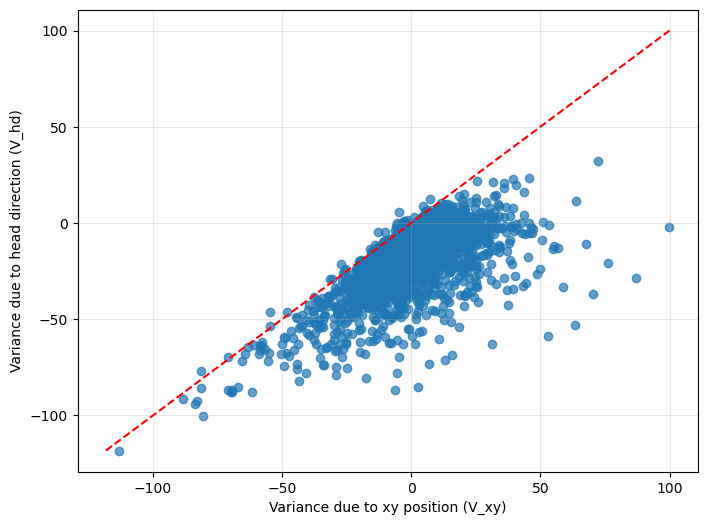

In [141]:
layer_idx = 0
layer = layers[layer_idx]

avg_xy = np.nanmean(layer_results[layer_idx]['xy'], axis=0)
avg_hd = np.nanmean(layer_results[layer_idx]['hd'], axis=0)

plt.figure(figsize=(8, 6))
plt.scatter(avg_xy, avg_hd, alpha=0.7)
plt.plot([min(avg_xy.min(), avg_hd.min()), max(avg_xy.max(), avg_hd.max())], 
         [min(avg_xy.min(), avg_hd.min()), max(avg_xy.max(), avg_hd.max())], 
         color='red', linestyle='--')
#plt.title(f'Variance Components per Neuron, Layer {layer}')
plt.xlabel('Variance due to xy position (V_xy)')
plt.ylabel('Variance due to head direction (V_hd)')
#plt.xlim(0, 200)
#plt.ylim(0, 200)
plt.grid(alpha=0.3)

plt.savefig(f'variance_comp_per_neuron_{model_name}_{layer}.svg')
plt.show()

In [134]:
heatmap_test = np.load('/home/mag/Space/results/pfeiffer/hd_rate_map_seed_111_fold0_hd_bin_count_17.npy')
heatmap_train = np.load('/home/mag/Space/results/pfeiffer/hd_rate_map_seed_111_fold1_hd_bin_count_17.npy')

n_neurons = heatmap_test.shape[3]
var_xy = np.zeros(n_neurons)
var_hd = np.zeros(n_neurons)

for n_idx in range(n_neurons):
    train = heatmap_train[:, :, :, n_idx].reshape(17 * 17, 17)
    test = heatmap_test[:, :, :, n_idx].reshape(17 * 17, 17)
    var_xy[n_idx] = quantify_variance(train, test, axis=0)[0]
    var_hd[n_idx] = quantify_variance(train, test, axis=1)[0]

avg_var_xy = np.nanmean(var_xy)
avg_var_hd = np.nanmean(var_hd)

print(avg_var_hd / (avg_var_hd + avg_var_xy))

0.3330904114713077


/tmp/ipykernel_2221394/2911619236.py:10: RuntimeWarning:

Mean of empty slice

/tmp/ipykernel_2221394/2911619236.py:11: RuntimeWarning:

Mean of empty slice



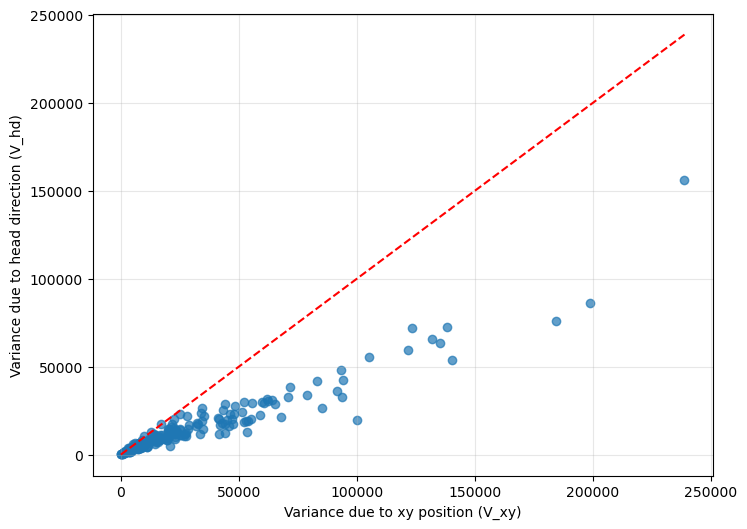

In [135]:

plt.figure(figsize=(8, 6))
plt.scatter(var_xy, var_hd, alpha=0.7)
plt.plot([0, max(var_xy.max(), var_hd.max())], 
         [0, max(var_xy.max(), var_hd.max())], 
         color='red', linestyle='--')
#plt.title('Variance Components per Neuron, Real Data')
plt.xlabel('Variance due to xy position (V_xy)')
plt.ylabel('Variance due to head direction (V_hd)')
#plt.xlim(0, 3000)
#plt.ylim(0, 3000)
plt.grid(alpha=0.3)

plt.savefig('variance_comp_per_neuron_pfeiffer_full.svg')
plt.show()


In [278]:
import os
from tqdm import tqdm

n_bins = 10

raw_sets = []

dataset = 'dusz'

if dataset == 'pfeiffer':
    path = '/home/mag/variance-analysis/results/pfeiffer/'
    for session in tqdm(os.listdir(path)):
        if 'Rat' not in session:
            continue
    
        raw_sets.append(np.load(f'{path}/{session}/Open1/xy_hd_raw_visits_{n_bins}_{n_bins}.npz')['visits'])  # this odesn't exist lol fr
    
else:
    path = '/home/mag/variance-analysis/results/dusz/Dataset_6'
    for session in os.listdir(path):
        if 'A' not in session:
            continue
    
        raw_sets.append(np.load(f'{path}/{session}/xy_hd_raw_visits_{n_bins}_{n_bins}_{n_bins}.npy')) 


In [262]:
raw_sets[0].shape

(10, 10, 10, 500, 6)

In [146]:
raw_sets = [np.load('/home/mag/variance-analysis/results/dusz/Dataset_6/A1106-180418/xy_hd_raw_visits_11_11_17.npy')]


In [258]:
def get_splits(
        visits, # s1_dim, s2_dim, n_max_visits, n_neurons
        min_visits=2,
        cap=False,
        seed=None
):
    """
    Randomly halves the samples in each bin → train / test splits.

    Returns
    -------
    train_mean, test_mean : mean spike count in each bin (nan if <min_visits)
    train_occ,  test_occ  : visit counts assigned to each split
    """
    rng = np.random.default_rng(seed)
    
    num_bins_s1 = visits.shape[0]
    num_bins_s2 = visits.shape[1]
    max_visits = visits.shape[2]
    n_neurons = visits.shape[3]

    total_mean = np.full((num_bins_s1, num_bins_s2, n_neurons), np.nan)
    train_mean = np.full((num_bins_s1, num_bins_s2, n_neurons), np.nan)
    test_mean  = np.full((num_bins_s1, num_bins_s2, n_neurons), np.nan)
    train_occ  = np.full((num_bins_s1, num_bins_s2), 0)
    test_occ   = np.full((num_bins_s1, num_bins_s2), 0)

    for s1 in range(num_bins_s1):
        for s2 in range(num_bins_s2):
            for n in range(n_neurons):
                n_visits = np.count_nonzero(~np.isnan(visits[s1, s2, :, n]))
                if n_visits >= min_visits:
                    take_n = min_visits if cap else n_visits
                    visit_split = visits[s1, s2, :take_n, n]#[s1, s2, :cap, n]
                    rng.shuffle(visit_split)
                    half = len(visit_split) // 2
                    train, test = visit_split[:half], visit_split[half:]
                    
                    train_mean[s1, s2, n] = np.nanmean(train)
                    test_mean[s1,  s2, n] = np.nanmean(test)
                    total_mean[s1, s2, n] = np.nanmean(visit_split)
                    train_occ[s1, s2] = half
                    test_occ[s1, s2] = half
                else:
                    train_occ[s1, s2] = 0
                    test_occ[s1, s2] = 0

    return total_mean, train_mean, test_mean, train_occ, test_occ

In [219]:
len(raw_sets)

21

In [342]:
from tqdm import tqdm
from scipy.ndimage import gaussian_filter, zoom

import os
from tqdm import tqdm

n_bins = 10

raw_sets = []

dataset = 'dusz'

if dataset == 'pfeiffer':
    path = '/home/mag/variance-analysis/results/pfeiffer'
    for session in tqdm(os.listdir(path)):
        if 'Rat' not in session:
            continue
    
        raw_sets.append(np.load(f'{path}/{session}/Open1/xy_hd_raw_visits_{n_bins}_{n_bins}.npz')['visits'])  # ???
    
else:
    path = '/home/mag/variance-analysis/results/dusz/Dataset_6'
    for session in os.listdir(path):
        if 'A' not in session:
            continue
    
        raw_sets.append(np.load(f'{path}/{session}/xy_hd_raw_visits_{n_bins}_{n_bins}_{n_bins}.npy')) 


smooth_sigma = 1.
upsample_factor = 2

var_s1 = []
var_s2 = []

var_s1_zoom = []
var_s2_zoom = []

#var_s1_20 = []
#var_s2_20 = []

n_splits = 10 # the number of times you wanna reshuffle and split the visits to a bin to calculate fold rate maps

for visits in tqdm(raw_sets): # if this is 1
    n_neurons = visits.shape[4]

    v_s1 = np.zeros((n_splits, n_neurons))
    v_s2 = np.zeros((n_splits, n_neurons))
    v_s1_z = np.zeros((n_splits, n_neurons))
    v_s2_z = np.zeros((n_splits, n_neurons))
    
    for s in range(n_splits):
        total, train, test, train_occ, test_occ = get_splits(visits, min_visits=2, cap=False, seed=s)
        
        for n_idx in range(n_neurons): 
            fold0_map = train[:, :, n_idx]
            fold1_map = test[:, :, n_idx]
            
            v_s1[s, n_idx] = quantify_variance(fold0_map, fold1_map, axis=0)[0]
            v_s2[s, n_idx] = quantify_variance(fold0_map, fold1_map, axis=1)[0]

            fold0_smooth = gaussian_filter(fold0_map, sigma=smooth_sigma)
            fold1_smooth = gaussian_filter(fold1_map, sigma=smooth_sigma)
    
            fold0_fine = zoom(fold0_smooth, upsample_factor, order=2)
            fold1_fine = zoom(fold1_smooth, upsample_factor, order=2)
            
            v_s1_z[s, n_idx] = quantify_variance(fold0_fine, fold1_fine, axis=0, verbose=False)[0]
            v_s2_z[s, n_idx] = quantify_variance(fold0_fine, fold1_fine, axis=1, verbose=False)[0]

    var_s1.append(v_s1.mean(axis=0))
    var_s2.append(v_s2.mean(axis=0))
    var_s1_zoom.append(v_s1_z.mean(axis=0))
    var_s2_zoom.append(v_s2_z.mean(axis=0))

  0%|                                                                                                   | 0/21 [00:00<?, ?it/s]/tmp/ipykernel_1958161/1629087761.py:39: RuntimeWarning: Mean of empty slice
  train_mean[s1, s2, n] = np.nanmean(train)
/tmp/ipykernel_1958161/1629087761.py:40: RuntimeWarning: Mean of empty slice
  test_mean[s1,  s2, n] = np.nanmean(test)
/tmp/ipykernel_1958161/1629087761.py:41: RuntimeWarning: Mean of empty slice
  total_mean[s1, s2, n] = np.nanmean(visit_split)
/tmp/ipykernel_1958161/1451279879.py:10: RuntimeWarning: Mean of empty slice
  test_mean = np.nanmean(heatmap_test, axis=axis)
/tmp/ipykernel_1958161/1451279879.py:11: RuntimeWarning: Mean of empty slice
  train_mean = np.nanmean(heatmap_train, axis=axis)
 10%|████████▋                                                                                  | 2/21 [00:37<06:00, 18.98s/it]


KeyboardInterrupt: 

In [336]:
import os
import numpy as np
from tqdm import tqdm
from scipy.ndimage import gaussian_filter, zoom

# -----------------------
# Config you might tweak
# -----------------------
dataset = 'pfeiffer'          # or 'pfeiffer'
smooth_sigma = 1.0
upsample_factor = 2 #(2, 2)       # 10 -> 20 via zoom
n_splits = 5             # reshuffles for split-half maps
min_visits = 2
cap = False

# -----------------------
# Outputs (per-session lists of per-neuron values)
# -----------------------
var_s1_10 = []
var_s2_10 = []
var_s1_10_zoom = []
var_s2_10_zoom = []

var_s1_20 = []
var_s2_20 = []

# -----------------------
# Helper: load sessions for a given bin count (no functions, just inline logic)
# -----------------------
for current_bins in [10]:#, 20]:
    raw_sets = []

    if dataset == 'pfeiffer':
        path = '/home/mag/variance-analysis/results/pfeiffer/'
        # files look like: xy_hd_raw_visits_{bins}_{bins}.npz with key 'visits' under .../Open1/
        for session in tqdm(os.listdir(path), desc=f'Loading {dataset} ({current_bins} bins)'):
            if 'Rat' not in session:
                continue
            npz_path = f'{path}/{session}/Open1/xy_hd_raw_visits_{current_bins}_{current_bins}.npz'
            if not os.path.exists(npz_path):
                continue
            raw_sets.append(np.load(npz_path)['visits'])

    else:  # 'dusz'
        path = '/home/mag/variance-analysis/results/dusz/Dataset_6'
        # files look like: xy_hd_raw_visits_{bins}_{bins}_{bins}.npy
        for session in tqdm(os.listdir(path), desc=f'Loading {dataset} ({current_bins} bins)'):
            if 'A' not in session:
                continue
            npy_path = f'{path}/{session}/xy_hd_raw_visits_{current_bins}_{current_bins}_{current_bins}.npy' # xy hd are 3d in the stimulus dimension, unlike md_hd
            if not os.path.exists(npy_path):
                continue
            raw_sets.append(np.load(npy_path).reshape(current_bins*current_bins, current_bins, 500, -1))

    # Skip if nothing loaded
    if len(raw_sets) == 0:
        print(f'No sessions found for {current_bins} bins; skipping.')
        continue

    # -----------------------
    # Per-bin processing (mirrors your original structure)
    # -----------------------
    var_s1 = []       # per-session means across splits, axis=0
    var_s2 = []       # per-session means across splits, axis=1
    var_s1_zoom = []  # only filled when current_bins == 10
    var_s2_zoom = []

    for visits in tqdm(raw_sets, desc=f'Processing ({current_bins} bins)'):
        # Peek once to size arrays robustly (some raw visit tensors are higher-dim)
        # Use the split output shape to get n_neurons safely.
        _total, _train0, _test0, _train_occ0, _test_occ0 = get_splits(
            visits, min_visits=min_visits, cap=cap, seed=0
        )
        n_neurons = _train0.shape[-1]

        v_s1 = np.zeros((n_splits, n_neurons))
        v_s2 = np.zeros((n_splits, n_neurons))

        # Only allocate zoom arrays for the 10-bin pass
        if current_bins == 10:
            v_s1_z = np.zeros((n_splits, n_neurons))
            v_s2_z = np.zeros((n_splits, n_neurons))

        for s in range(n_splits):
            total, train, test, train_occ, test_occ = get_splits(
                visits, min_visits=min_visits, cap=cap, seed=s
            )

            # Per-neuron split-half maps
            for n_idx in range(n_neurons):
                fold0_map = train[:, :, n_idx]
                fold1_map = test[:, :, n_idx]

                # Raw (current_bins)
                v_s1[s, n_idx] = quantify_variance(fold0_map, fold1_map, axis=0)[0]
                v_s2[s, n_idx] = quantify_variance(fold0_map, fold1_map, axis=1)[0]

                # Zoomed only for the 10-bin case (10 -> 20 via interpolation)
                if current_bins == 10:
                    fold0_smooth = gaussian_filter(fold0_map, sigma=smooth_sigma)
                    fold1_smooth = gaussian_filter(fold1_map, sigma=smooth_sigma)

                    fold0_fine = zoom(fold0_smooth, upsample_factor, order=2)
                    fold1_fine = zoom(fold1_smooth, upsample_factor, order=2)

                    v_s1_z[s, n_idx] = quantify_variance(fold0_fine, fold1_fine, axis=0, verbose=False)[0]
                    v_s2_z[s, n_idx] = quantify_variance(fold0_fine, fold1_fine, axis=1, verbose=False)[0]

        # Average across reshuffles/splits for this session
        var_s1.append(v_s1.mean(axis=0))
        var_s2.append(v_s2.mean(axis=0))
        if current_bins == 10:
            var_s1_zoom.append(v_s1_z.mean(axis=0))
            var_s2_zoom.append(v_s2_z.mean(axis=0))

    # -----------------------
    # Assign to the final outputs you wanted
    # -----------------------
    if current_bins == 10:
        var_s1_10 = var_s1
        var_s2_10 = var_s2
        var_s1_10_zoom = var_s1_zoom
        var_s2_10_zoom = var_s2_zoom
    else:  # 20 bins
        var_s1_20 = var_s1
        var_s2_20 = var_s2

# -----------------------
# Done. You now have:
#   var_s1_10, var_s2_10           -> 10 bins
#   var_s1_10_zoom, var_s2_10_zoom -> 10 bins, zoomed to 20
#   var_s1_20, var_s2_20           -> native 20 bins
# Each is a list (over sessions) of 1D arrays (over neurons).
# -----------------------

# Optional: quick sanity prints
print('10 bins:        ', len(var_s1_10), 'sessions')
print('10 bins zoomed: ', len(var_s1_10_zoom), 'sessions')
print('20 bins:        ', len(var_s1_20), 'sessions')



Loading pfeiffer (10 bins): 100%|████████████████████████████████████████████████████████████| 30/30 [00:00<00:00, 1136.15it/s]

No sessions found for 10 bins; skipping.
10 bins:         0 sessions
10 bins zoomed:  0 sessions
20 bins:         0 sessions


In [337]:
raw_sets[0].shape

IndexError: list index out of range

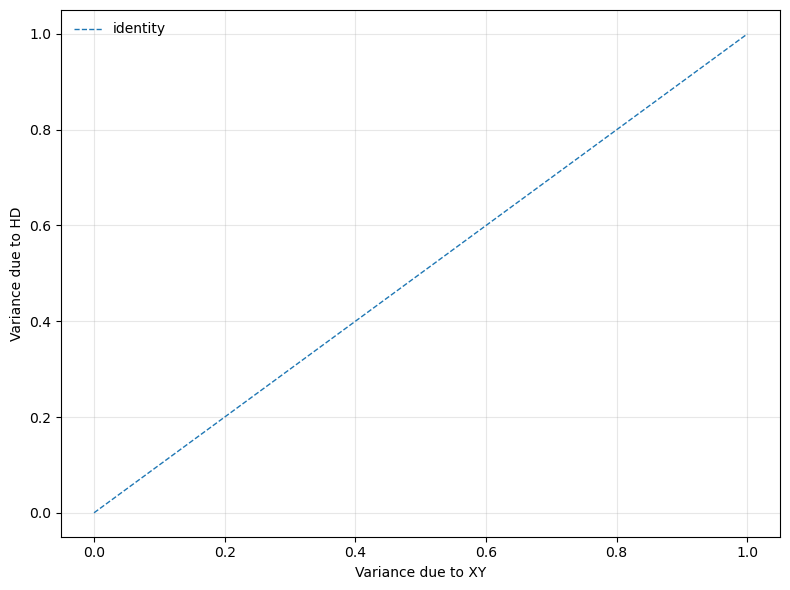

In [338]:
# Adds per-series OLS trend lines (slope/intercept/R^2) to your existing scatter plot.
# Robust to missing variables (falls back to []), skips empty sets automatically.

import numpy as np
import matplotlib.pyplot as plt

def _safe_get(*names, default=None):
    """Return the first existing global var by name; else default."""
    g = globals()
    for n in names:
        if n in g:
            return g[n]
    return default

# --- Backward-compatible refs (robust lookups) ---
vs1_10 = _safe_get('var_s1_10', 'var_s1', default=[])
vs2_10 = _safe_get('var_s2_10', 'var_s2', default=[])

vs1_10z = _safe_get('var_s1_10_zoom', 'var_s1_zoom', default=[])
vs2_10z = _safe_get('var_s2_10_zoom', 'var_s2_zoom', default=[])

vs1_20 = _safe_get('var_s1_20', default=[])
vs2_20 = _safe_get('var_s2_20', default=[])

# --- Safe flatten (handles per-session arrays/lists) ---
def _flat(lst):
    return np.concatenate([np.ravel(x) for x in lst]) if lst else np.array([])

var_s1_10_bins      = _flat(vs1_10)
var_s2_10_bins      = _flat(vs2_10)
var_s1_10_zoom_bins = _flat(vs1_10z)
var_s2_10_zoom_bins = _flat(vs2_10z)
var_s1_20_bins      = _flat(vs1_20)
var_s2_20_bins      = _flat(vs2_20)

def _fit_and_plot(x, y, label):
    """Fit y = a*x + b via OLS, plot the line, and return (a, b, R^2)."""
    if x.size == 0 or y.size == 0:
        return None
    msk = np.isfinite(x) & np.isfinite(y)
    if msk.sum() < 2:
        return None
    a, b = np.polyfit(x[msk], y[msk], 1)
    r = np.corrcoef(x[msk], y[msk])[0, 1]
    r2 = float(r * r)
    x_line = np.array([x[msk].min(), x[msk].max()])
    y_line = a * x_line + b
    # Do not set explicit colors; let Matplotlib choose. Comply with "one chart, no specific colors".
    plt.plot(x_line, y_line, linewidth=2, linestyle='-')
    return a, b, r2

# --- Plot ---
plt.figure(figsize=(8, 6))

if var_s1_10_bins.size and var_s2_10_bins.size:
    plt.scatter(var_s1_10_bins, var_s2_10_bins, alpha=0.2, label='10 bins')
    _fit_and_plot(var_s1_10_bins, var_s2_10_bins, '10 bins')

if var_s1_10_zoom_bins.size and var_s2_10_zoom_bins.size:
    plt.scatter(var_s1_10_zoom_bins, var_s2_10_zoom_bins, alpha=0.2, label='10→20 (zoomed)')
#    _fit_and_plot(var_s1_10_zoom_bins, var_s2_10_zoom_bins, '10→20 (zoomed)')

if var_s1_20_bins.size and var_s2_20_bins.size:
    plt.scatter(var_s1_20_bins, var_s2_20_bins, alpha=0.2, label='20 bins')
    _fit_and_plot(var_s1_20_bins, var_s2_20_bins, '20 bins')

# Identity line using the overall min/max across all arrays
cands = []
for arr in [var_s1_10_bins, var_s2_10_bins,
            var_s1_10_zoom_bins, var_s2_10_zoom_bins,
            var_s1_20_bins, var_s2_20_bins]:
    if arr.size:
        cands.append(arr.min())
        cands.append(arr.max())

if cands:
    mn, mx = float(np.min(cands)), float(np.max(cands))
    if np.isfinite(mn) and np.isfinite(mx) and mx != mn:
        plt.plot([mn, mx], [mn, mx], linestyle='--', linewidth=1, label='identity')
else:
    # Fallback identity range
    plt.plot([0, 1], [0, 1], linestyle='--', linewidth=1, label='identity')

plt.xlabel('Variance due to XY')
plt.ylabel('Variance due to HD')
plt.legend(frameon=False)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [335]:
vs1_10z

[array([0., 0., 0., 0., 0., 0.]),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 array([0., 0., 0., 0., 0.]),
 array([0.]),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 array([0., 0., 0., 0., 0., 0., 0., 0.]),
 array([0., 0., 0., 0.]),
 array([0., 0., 0., 0., 0.]),
 array([0.]),
 array([0., 0., 0., 0., 0., 0.]),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 array([0., 0., 0., 0.]),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0.]),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 array([0., 0., 0.]),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0.

In [248]:
np.min(var_s1)

-0.22754280427830498

## Doing this without the raw rate maps

In [169]:
import os

n_bins = 20

train_sets = []
test_sets = []

path = '/home/mag/variance-analysis/results/dusz/Dataset_6'

for session in os.listdir(path):
    if 'A' not in session:
        continue

    train_sets.append(np.load(f'{path}/{session}/hd_md_rate_map_fold0_{n_bins}_{n_bins}.npy')) 
    test_sets.append(np.load(f'{path}/{session}/hd_md_rate_map_fold1_{n_bins}_{n_bins}.npy')) 


In [157]:
len(test_sets)

21

In [170]:
from scipy.ndimage import gaussian_filter, zoom

smooth_sigma = 1.5
upsample_factor = 2

var_xy_20_bins = []
var_hd_20_bins = []

#var_xy_zoom = []
#var_hd_zoom = []

for i, (train, test) in enumerate(zip(train_sets, test_sets)):
    n_neurons = train.shape[2]

    for n_idx in range(n_neurons):

        fold0 = train[:, :, n_idx]
        fold1 = test[:, :, n_idx]
        
        var_xy_20_bins.append(quantify_variance(fold0, fold1, axis=0)[0])
        var_hd_20_bins.append(quantify_variance(fold0, fold1, axis=1)[0])

        '''
        fold0_smooth = gaussian_filter(fold0, sigma=smooth_sigma)
        fold1_smooth = gaussian_filter(fold1, sigma=smooth_sigma)

        fold0_fine = zoom(fold0_smooth, upsample_factor, order=2)
        fold1_fine = zoom(fold1_smooth, upsample_factor, order=2)
        
        var_xy_zoom.append(quantify_variance(fold0_fine, fold1_fine, axis=0)[0])
        var_hd_zoom.append(quantify_variance(fold0_fine, fold1_fine, axis=1)[0])
        '''
        
        

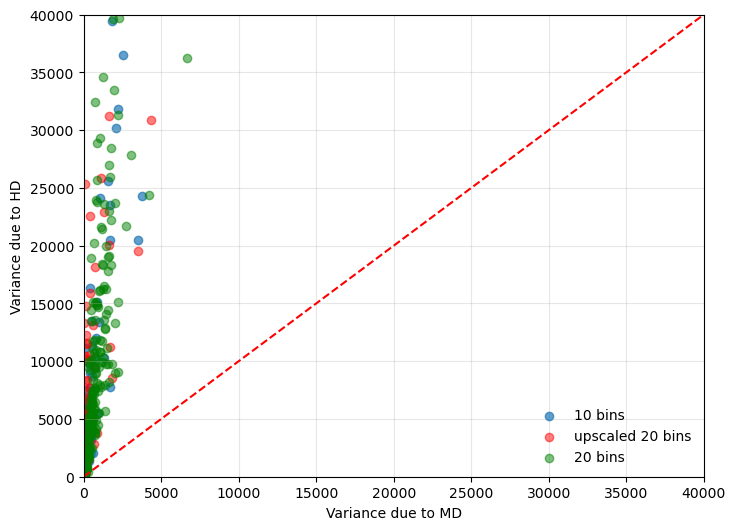

In [183]:

var_xy = np.array(var_xy)
var_hd = np.array(var_hd)
var_xy_zoom = np.array(var_xy_zoom)
var_hd_zoom = np.array(var_hd_zoom)
var_xy_20_bins = np.array(var_xy_20_bins)
var_hd_20_bins = np.array(var_hd_20_bins)

plt.figure(figsize=(8, 6))
plt.scatter(var_xy, var_hd, alpha=0.7, label='10 bins')
plt.scatter(var_xy_zoom, var_hd_zoom, color='red', alpha=0.5, label='upscaled 20 bins')
plt.scatter(var_xy_20_bins, var_hd_20_bins, color='green', alpha=0.5, label='20 bins')
plt.plot([0, max(var_xy.max(), var_hd.max())], 
         [0, max(var_xy.max(), var_hd.max())], 
         color='red', linestyle='--')
#plt.title('Variance Components per Neuron, Real Data')
plt.xlabel('Variance due to MD')
plt.ylabel('Variance due to HD')
plt.legend(frameon=False)
#lim = 300000
plt.xlim(-10, 40000)
plt.ylim(-10, 40000)
plt.grid(alpha=0.3)

#plt.savefig(f'variance_comp_per_neuron_dusz_full_{n_bins}_{lim}.png')
plt.show()


## New way of plotting this

In [177]:
np.min(var_xy_zoom)

0.01660548708360219